# 15 — Final Charts

**December wrap-up · Task 18 · final charts and visuals.** Nine
presentation-ready figures, one per slide-sized idea, each titled with its
takeaway rather than its axes. `final_00` is the one-slide summary of the
final model (best model, accuracy, top input features, why it was picked).

Everything is recomputed here rather than read from saved files, so the
figures cannot drift from the code and do not depend on any one person's
results having been saved. Runs in a few minutes (it refits three models).

Output: `reports/figures/final_00_*.png` ... `final_08_*.png`

Charts 0 and 8 read the feature-importance table and model card that
`09_final_model.ipynb` writes, so run 09 first.

In [1]:
import sys
import warnings
from pathlib import Path

warnings.filterwarnings("ignore")
sys.path.insert(0, str(Path.cwd().parent))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl

from src.loading import load_raw
from src.cleaning import clean
from src.features import build_model_matrix
from src.modeling import make_models, align_columns, make_final_model, FINAL_MODEL_NAME
import json
from src.evaluation import evaluate, majority_class_baseline
from src.prepare import load_splits
from src.recommend import (
    Recommender, RAW_COLUMNS, BANDS, GOAL_FACTORS, DURATION_TARGETS, TIER_TARGETS,
    MIN_TIER_ADDITION, DEFAULT_DURATION, EXTRA,
)

TEAL, PLUM, CORAL, SAND, GREY = "#2E7D6F", "#7B5EA7", "#C0392B", "#D9A455", "#8A8F94"
mpl.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "font.size": 12,
    "axes.titlesize": 14, "axes.titleweight": "bold", "axes.labelsize": 12,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25, "axes.axisbelow": True,
})
FIG = Path("../reports/figures")

def save(fig, name):
    fig.savefig(FIG / name, bbox_inches="tight", facecolor="white")
    plt.show()
    print("saved", name)

splits = load_splits("..")
train, test = splits["random"]
train_c, test_c = splits["chronological"]
rec = Recommender.fit(train, test=test)
print(f"train {len(train):,}   test {len(test):,}")

train 30,702   test 7,676


## 0. The final model on one slide

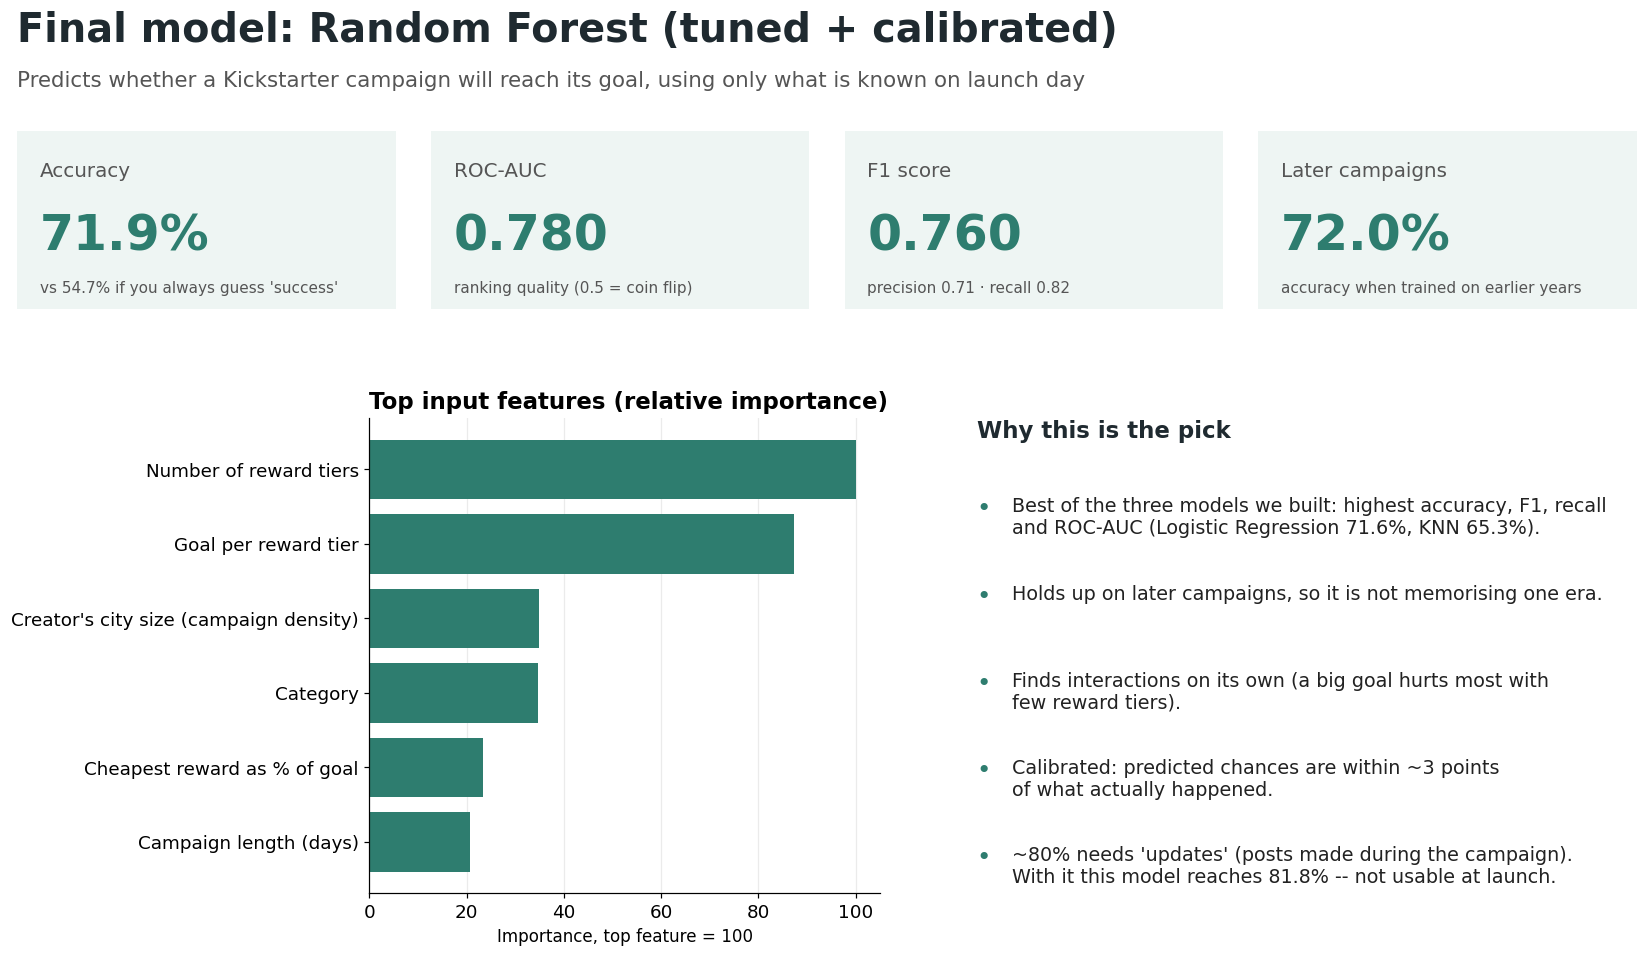

saved final_00_best_model_summary.png


In [2]:
card = json.loads(Path("../reports/m3_model_card.json").read_text())
imp = pd.read_csv("../reports/m3_final_feature_importance.csv")
X_tr0, y_tr0 = build_model_matrix(train, "launch_only", extra_numeric=EXTRA)
X_te0, y_te0 = build_model_matrix(test, "launch_only", extra_numeric=EXTRA)
X_te0 = align_columns(X_tr0, X_te0)
lr0 = make_models()["Logistic Regression"].fit(X_tr0, y_tr0)
lr_row = evaluate(lr0, X_te0, y_te0, label="LR").iloc[0]
floor0 = majority_class_baseline(train["success"], test["success"]).iloc[0]

fig = plt.figure(figsize=(16, 9))
fig.patch.set_facecolor("white")
fig.text(0.04, 0.93, "Final model: Random Forest (tuned + calibrated)", fontsize=26,
         fontweight="bold", color="#1F2A30")
fig.text(0.04, 0.885, "Predicts whether a Kickstarter campaign will reach its goal, using only what is "
         "known on launch day", fontsize=14, color="#555")

# --- metric tiles
tiles = [("Accuracy", f"{card['accuracy']:.1%}", f"vs {floor0['accuracy']:.1%} if you always guess 'success'"),
         ("ROC-AUC", f"{card['roc_auc']:.3f}", "ranking quality (0.5 = coin flip)"),
         ("F1 score", f"{card['f1']:.3f}", f"precision {card['precision']:.2f} · recall {card['recall']:.2f}"),
         ("Later campaigns", f"{card['chronological_accuracy']:.1%}", "accuracy when trained on earlier years")]
for i, (name, val, sub) in enumerate(tiles):
    ax = fig.add_axes([0.04 + i * 0.235, 0.66, 0.215, 0.18])
    ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
    for s in ax.spines.values():
        s.set_visible(False)
    ax.set_facecolor("#EEF5F3")
    ax.text(0.06, 0.74, name, fontsize=13, color="#555", transform=ax.transAxes)
    ax.text(0.06, 0.33, val, fontsize=32, fontweight="bold", color=TEAL, transform=ax.transAxes)
    ax.text(0.06, 0.09, sub, fontsize=10, color="#555", transform=ax.transAxes)

# --- top features
ax = fig.add_axes([0.24, 0.07, 0.29, 0.48])
top = imp.head(6).iloc[::-1]
ax.barh(top["label"], top["importance"] / imp["importance"].head(6).max() * 100, color=TEAL)
ax.set_title("Top input features (relative importance)", loc="left", fontsize=15)
ax.set_xlabel("Importance, top feature = 100", fontsize=11)
ax.tick_params(axis="y", labelsize=12); ax.grid(axis="y", visible=False)

# --- why
why = [
    f"Best of the three models we built: highest accuracy, F1, recall\nand ROC-AUC (Logistic Regression {lr_row['accuracy']:.1%}, KNN 65.3%).",
    "Holds up on later campaigns, so it is not memorising one era.",
    "Finds interactions on its own (a big goal hurts most with\nfew reward tiers).",
    f"Calibrated: predicted chances are within ~{card['largest_calibration_gap_pts']:.0f} points\nof what actually happened.",
    f"~80% needs 'updates' (posts made during the campaign).\nWith it this model reaches {card['mid_campaign_accuracy_with_updates']:.1%} -- not usable at launch.",
]
fig.text(0.585, 0.53, "Why this is the pick", fontsize=15, fontweight="bold", color="#1F2A30")
for i, w_ in enumerate(why):
    fig.text(0.585, 0.47 - i * 0.088, "•", fontsize=16, color=TEAL, va="top")
    fig.text(0.605, 0.47 - i * 0.088, w_, fontsize=12.5, color="#222", va="top")
save(fig, "final_00_best_model_summary.png")

## 8. Top input features (standalone)

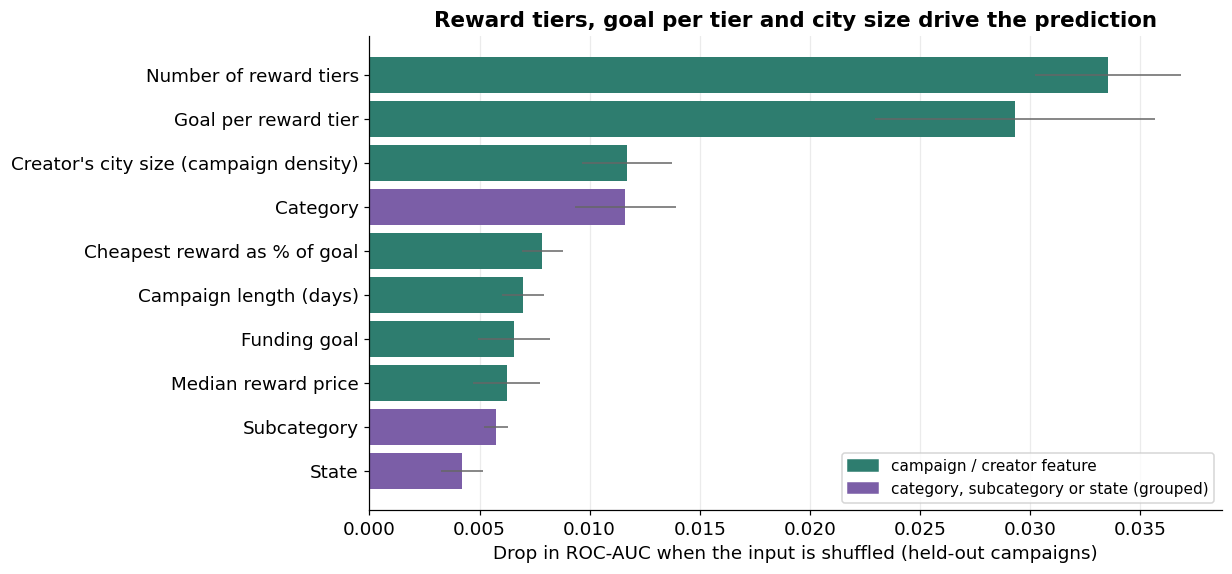

saved final_08_top_features.png


In [3]:
top = imp.head(10).iloc[::-1]
grp_color = lambda f: PLUM if f in ("category", "subcategory", "state") else TEAL
fig, ax = plt.subplots(figsize=(10, 5.6))
ax.barh(top["label"], top["importance"], xerr=top["std"], color=[grp_color(f) for f in top["feature"]],
        error_kw={"ecolor": "#666", "lw": 1})
ax.set_xlabel("Drop in ROC-AUC when the input is shuffled (held-out campaigns)")
ax.set_title("Reward tiers, goal per tier and city size drive the prediction")
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in (TEAL, PLUM)]
ax.legend(handles, ["campaign / creator feature", "category, subcategory or state (grouped)"],
          loc="lower right", fontsize=10)
ax.grid(axis="y", visible=False)
save(fig, "final_08_top_features.png")

## 1. From a raw scrape to a modelling table

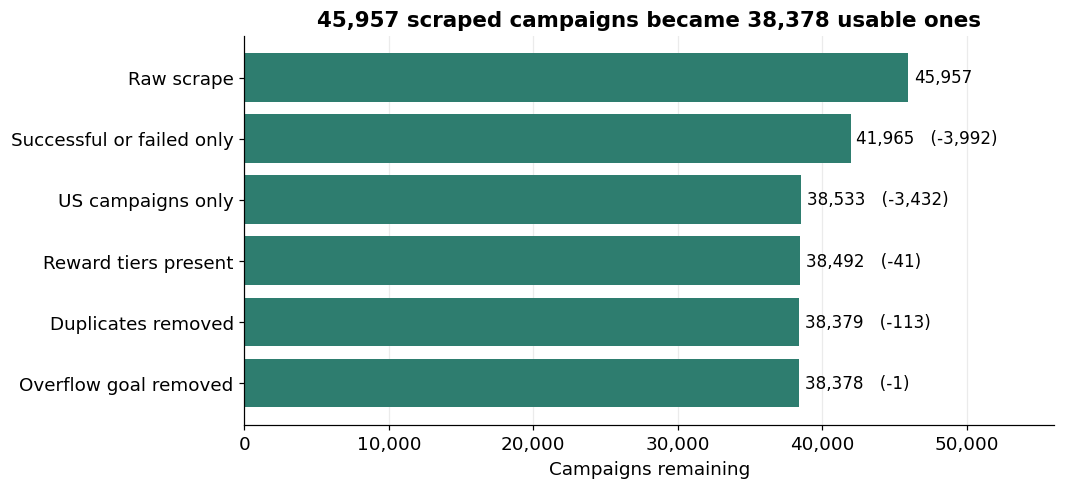

saved final_01_data_funnel.png


In [4]:
raw = load_raw("../data/DSI_kickstarterscrape_dataset_csv.zip")
_, log = clean(raw, verbose=False)
labels = {"raw": "Raw scrape", "filter_status": "Successful or failed only",
          "filter_us": "US campaigns only", "drop_missing_reward_levels": "Reward tiers present",
          "dedupe_project_id": "Duplicates removed", "drop_goal_sentinel": "Overflow goal removed"}
steps = log[(log["step"] == "raw") | (log["removed"] > 0)].copy()
steps["label"] = steps["step"].map(labels)

fig, ax = plt.subplots(figsize=(9.5, 4.6))
y = np.arange(len(steps))
ax.barh(y, steps["rows_after"], color=TEAL)
ax.set_yticks(y); ax.set_yticklabels(steps["label"]); ax.invert_yaxis()
for i, (n, rem) in enumerate(zip(steps["rows_after"], steps["removed"])):
    txt = f"{n:,}" + (f"   (-{rem:,})" if rem else "")
    ax.text(n + 400, i, txt, va="center", fontsize=11)
ax.set_xlim(0, steps["rows_after"].max() * 1.22)
ax.xaxis.set_major_formatter(mpl.ticker.FuncFormatter(lambda v, _: f"{int(v):,}"))
ax.set_xlabel("Campaigns remaining")
ax.set_title(f"{int(steps['rows_after'].iloc[0]):,} scraped campaigns became "
             f"{int(steps['rows_after'].iloc[-1]):,} usable ones")
ax.grid(axis="y", visible=False)
save(fig, "final_01_data_funnel.png")

## 2. What separates successful campaigns from failed ones

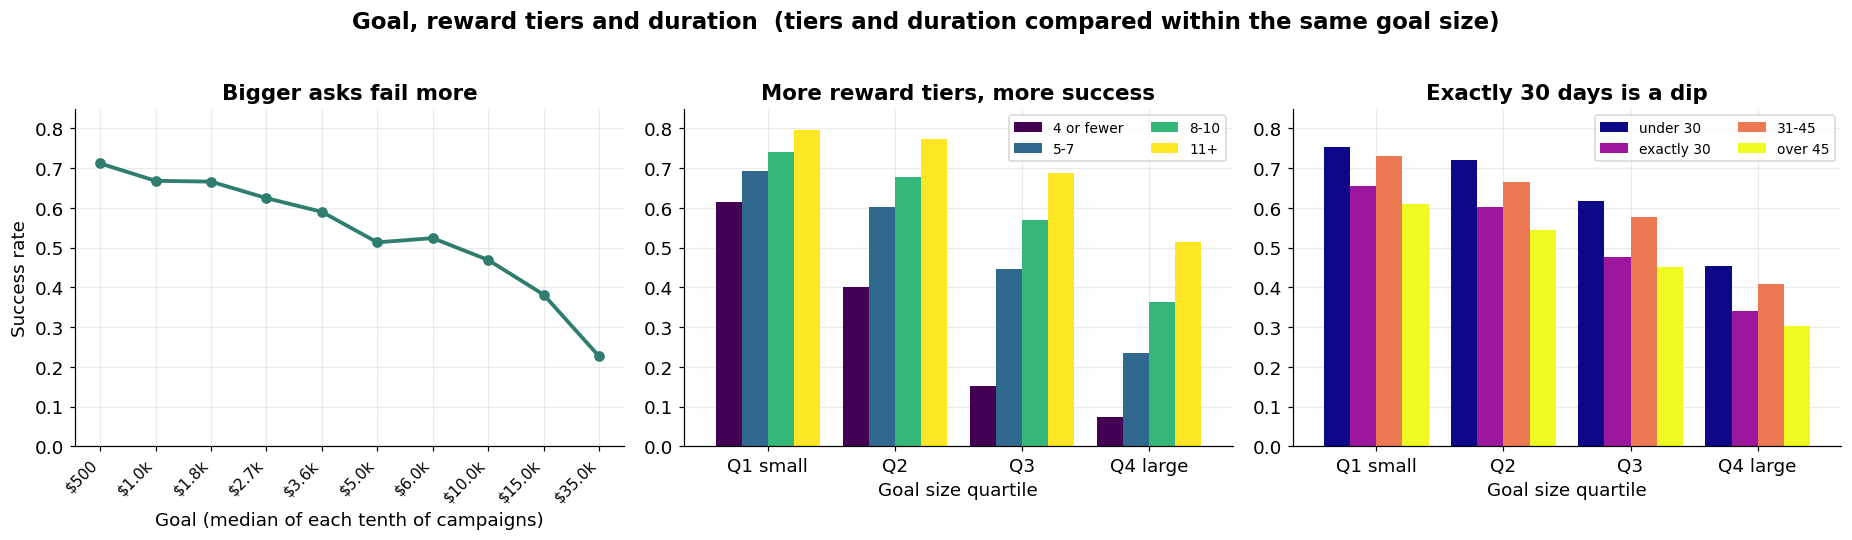

saved final_02_what_drives_success.png


In [5]:
t = train.copy()
t["goal_q"] = pd.qcut(t["goal"], 4, labels=["Q1 small", "Q2", "Q3", "Q4 large"])
t["goal_decile"] = pd.qcut(t["goal"], 10, duplicates="drop")
goal_ev = t.groupby("goal_decile", observed=True).agg(med=("goal", "median"), s=("success", "mean"))
t["tier_b"] = pd.cut(t["levels"], [0, 4, 7, 10, 100], labels=["4 or fewer", "5-7", "8-10", "11+"])
tier_ev = t.pivot_table(index="goal_q", columns="tier_b", values="success", aggfunc="mean", observed=True)
t["dur_b"] = pd.cut(t["duration_days"], [0, 29.5, 30.5, 45, 100],
                    labels=["under 30", "exactly 30", "31-45", "over 45"])
dur_ev = t.pivot_table(index="goal_q", columns="dur_b", values="success", aggfunc="mean", observed=True)

fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
ax = axes[0]
ax.plot(range(len(goal_ev)), goal_ev["s"], marker="o", color=TEAL, lw=2.5)
ax.set_xticks(range(len(goal_ev)))
ax.set_xticklabels([f"${v/1000:.1f}k" if v >= 1000 else f"${v:.0f}" for v in goal_ev["med"]],
                   rotation=45, ha="right", fontsize=10)
ax.set_ylabel("Success rate"); ax.set_ylim(0, 0.85)
ax.set_title("Bigger asks fail more")
ax.set_xlabel("Goal (median of each tenth of campaigns)")

for ax, ev, title, cmap in [(axes[1], tier_ev, "More reward tiers, more success", "viridis"),
                            (axes[2], dur_ev, "Exactly 30 days is a dip", "plasma")]:
    ev.plot.bar(ax=ax, width=0.82, rot=0, colormap=cmap)
    ax.set_title(title); ax.set_xlabel("Goal size quartile"); ax.set_ylim(0, 0.85)
    ax.legend(fontsize=9, title=None, ncol=2, loc="upper right")
axes[1].set_ylabel(""); axes[2].set_ylabel("")
fig.suptitle("Goal, reward tiers and duration  (tiers and duration compared within the same goal size)", y=1.02,
             fontsize=15, fontweight="bold")
plt.tight_layout()
save(fig, "final_02_what_drives_success.png")

## 3. How well can launch-time information predict success?

In [6]:
def fit_eval(label, key, feature_set, split="random"):
    X_tr, y_tr = build_model_matrix(train, feature_set, extra_numeric=EXTRA)
    X_te, y_te = build_model_matrix(test, feature_set, extra_numeric=EXTRA)
    X_te = align_columns(X_tr, X_te)
    m = make_final_model() if key == "final" else make_models()[key]
    m.fit(X_tr, y_tr)
    return evaluate(m, X_te, y_te, label=label, feature_set=feature_set, split=split)

res = pd.concat([
    fit_eval("Random Forest (final)", "final", "launch_only"),
    fit_eval("Logistic Regression", "Logistic Regression", "launch_only"),
    fit_eval("KNN", "KNN", "launch_only"),
    fit_eval("Logistic Regression", "Logistic Regression", "plus_campaign"),
    fit_eval("Random Forest (final)", "Random Forest", "plus_campaign"),
], ignore_index=True)
floor = majority_class_baseline(train["success"], test["success"]).iloc[0]
res.round(4)

,model,feature_set,split,accuracy,precision,recall,f1,roc_auc
0,Random Forest (final),launch_only,random,0.7187,0.7121,0.8160,0.7605,0.7800
1,Logistic Regression,launch_only,random,0.7160,0.7175,0.7936,0.7536,0.7770
2,KNN,launch_only,random,0.6528,0.6453,0.8119,0.7191,0.7026
3,Logistic Regression,plus_campaign,random,0.8158,0.8254,0.8415,0.8333,0.8936
4,Random Forest (final),plus_campaign,random,0.8180,0.8158,0.8622,0.8383,0.8972


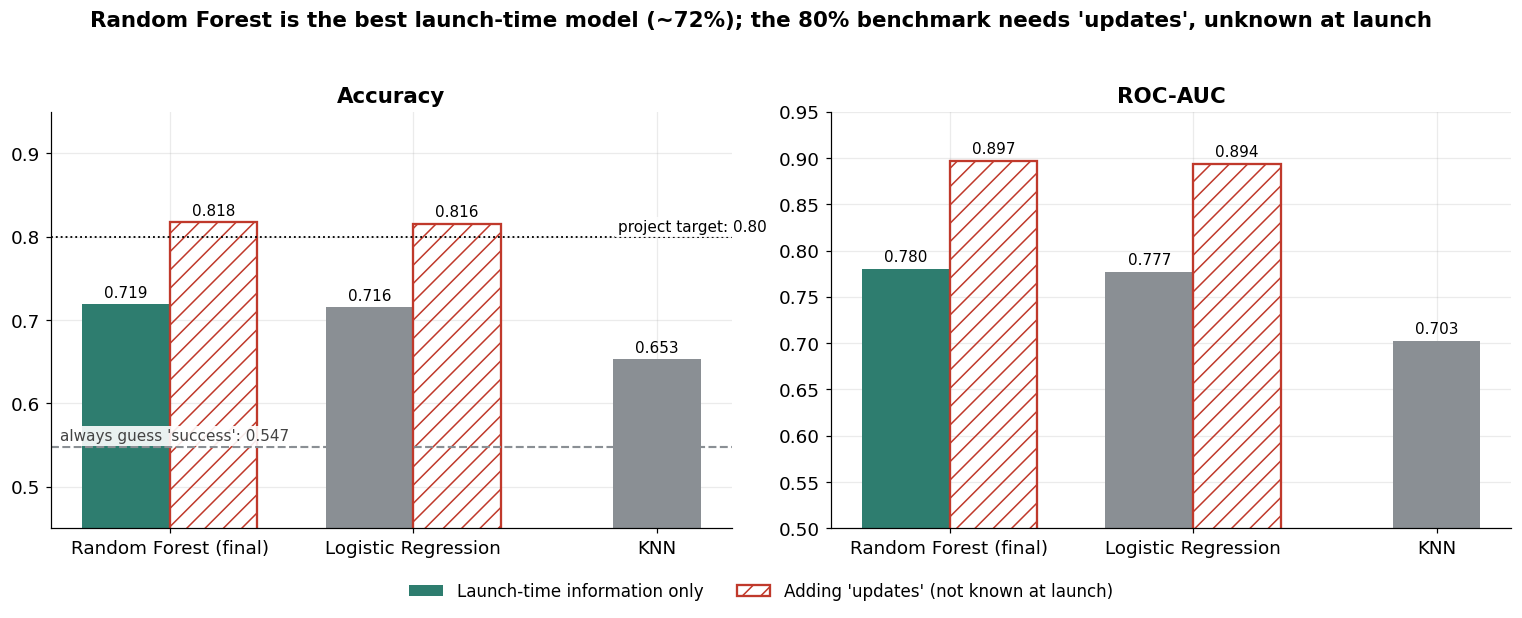

saved final_03_model_comparison.png


In [7]:
launch = res[res["feature_set"] == "launch_only"].set_index("model")
plus = res[res["feature_set"] == "plus_campaign"].set_index("model")
order = ["Random Forest (final)", "Logistic Regression", "KNN"]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, metric, title in [(axes[0], "accuracy", "Accuracy"), (axes[1], "roc_auc", "ROC-AUC")]:
    x = np.arange(len(order)); w = 0.36
    # a model with no "updates" counterpart (KNN) is drawn centred, not off to one side
    off = np.array([-w / 2 if m in plus.index else 0.0 for m in order])
    ax.bar(x + off, [launch.loc[m, metric] for m in order], w,
           color=[TEAL if m.startswith("Random Forest") else GREY for m in order],
           label="Launch-time information only")
    xs_plus = [i + w / 2 for i, m in enumerate(order) if m in plus.index]
    ax.bar(xs_plus, [plus.loc[m, metric] for m in order if m in plus.index], w,
           color="none", edgecolor=CORAL, hatch="//", lw=1.5,
           label="Adding 'updates' (not known at launch)")
    for i, m in enumerate(order):
        ax.text(i + off[i], launch.loc[m, metric] + 0.008, f"{launch.loc[m, metric]:.3f}",
                ha="center", fontsize=10)
        if m in plus.index:
            ax.text(i + w / 2, plus.loc[m, metric] + 0.008, f"{plus.loc[m, metric]:.3f}",
                    ha="center", fontsize=10)
    box = dict(facecolor="white", edgecolor="none", pad=1.5, alpha=0.9)
    if metric == "accuracy":
        ax.axhline(floor["accuracy"], color=GREY, ls="--", lw=1.4)
        ax.text(-0.45, floor["accuracy"] + 0.008, f"always guess 'success': {floor['accuracy']:.3f}",
                ha="left", fontsize=10, color="#444", bbox=box)
        ax.axhline(0.80, color="black", ls=":", lw=1.2)
        ax.text(2.45, 0.806, "project target: 0.80", ha="right", fontsize=10, bbox=box)
    ax.set_xticks(x); ax.set_xticklabels(order); ax.set_title(title)
    ax.set_ylim(0.45 if metric == "accuracy" else 0.5, 0.95)
h, l = axes[0].get_legend_handles_labels()
fig.legend(h, l, loc="lower center", ncol=2, fontsize=11, frameon=False, bbox_to_anchor=(0.5, -0.07))
fig.suptitle("Random Forest is the best launch-time model (~72%); the 80% benchmark needs 'updates', unknown at launch",
             y=1.03, fontsize=14, fontweight="bold")
plt.tight_layout()
save(fig, "final_03_model_comparison.png")

## 4. Can the probability be trusted?

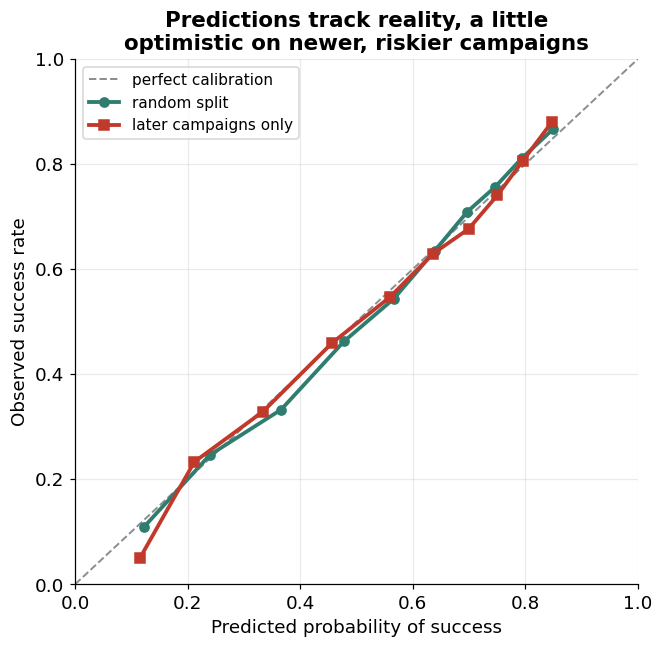

saved final_04_calibration.png


In [8]:
rec_c = Recommender.fit(train_c, test=test_c)

def cal(p, y):
    q = pd.qcut(p, 10, duplicates="drop")
    return pd.DataFrame({"p": p, "y": y}).groupby(q, observed=True).agg(pred=("p", "mean"), obs=("y", "mean"))

c_r, c_c = cal(rec.holdout_p, rec.holdout_y), cal(rec_c.holdout_p, rec_c.holdout_y)
fig, ax = plt.subplots(figsize=(6.6, 6.2))
ax.plot([0, 1], [0, 1], color=GREY, ls="--", lw=1.3, label="perfect calibration")
ax.plot(c_r["pred"], c_r["obs"], marker="o", color=TEAL, lw=2.5, label="random split")
ax.plot(c_c["pred"], c_c["obs"], marker="s", color=CORAL, lw=2.5, label="later campaigns only")
ax.set_xlabel("Predicted probability of success"); ax.set_ylabel("Observed success rate")
ax.set_title("Predictions track reality, a little\noptimistic on newer, riskier campaigns")
ax.legend(fontsize=10); ax.set_xlim(0, 1); ax.set_ylim(0, 1)
save(fig, "final_04_calibration.png")

## 5. Which changes does the model associate with better odds?

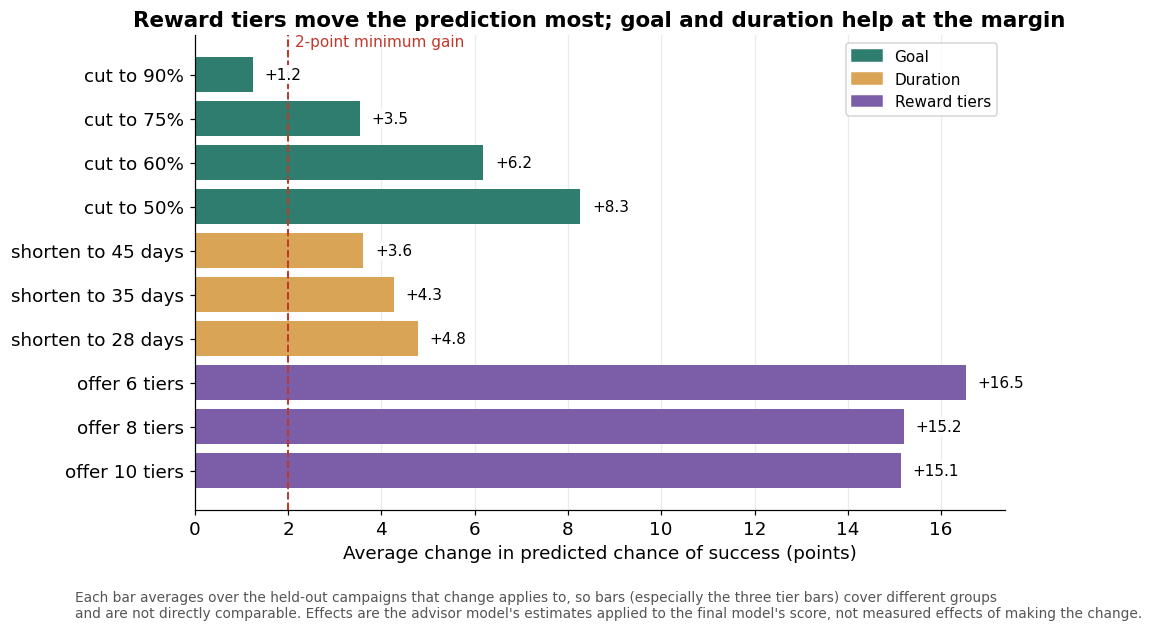

saved final_05_lever_effects.png


In [9]:
raw_test = test[RAW_COLUMNS].copy()

def gains(lever, value, rows):
    before = rec.predict_proba(rows)
    return (rec.what_if_proba(rows, rec.apply_lever(rows, lever, value), base=before) - before) * 100

rows_out = []
for f in GOAL_FACTORS:
    rows_out.append(("Goal", f"cut to {f:.0%}", gains("goal", f, raw_test).mean()))
dur = raw_test["duration"]
for tgt in sorted(DURATION_TARGETS, reverse=True):
    r = raw_test[(dur > DEFAULT_DURATION[1]) & (dur <= 60) & (dur > tgt + 0.5)]
    rows_out.append(("Duration", f"shorten to {tgt} days", gains("duration", tgt, r).mean()))
for tgt in TIER_TARGETS:
    r = raw_test[raw_test["levels"] <= tgt - MIN_TIER_ADDITION]
    r = r.sample(min(1500, len(r)), random_state=0)
    rows_out.append(("Reward tiers", f"offer {tgt} tiers", gains("reward tiers", tgt, r).mean()))
lev = pd.DataFrame(rows_out, columns=["lever", "change", "gain"])

colors = {"Goal": TEAL, "Duration": SAND, "Reward tiers": PLUM}
fig, ax = plt.subplots(figsize=(9.5, 5.6))
ax.barh(range(len(lev)), lev["gain"], color=[colors[l] for l in lev["lever"]])
ax.set_yticks(range(len(lev))); ax.set_yticklabels(lev["change"]); ax.invert_yaxis()
box = dict(facecolor="white", edgecolor="none", pad=1.2, alpha=0.9)
for i, g in enumerate(lev["gain"]):
    ax.text(g + 0.25, i, f"+{g:.1f}", va="center", fontsize=10, bbox=box)
ax.axvline(2, color=CORAL, ls="--", lw=1.3)
ax.text(2.15, -0.75, "2-point minimum gain", color=CORAL, fontsize=10, va="center")
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in colors.values()]
ax.legend(handles, colors.keys(), loc="upper right", fontsize=10)
ax.set_xlabel("Average change in predicted chance of success (points)")
ax.set_title("Reward tiers move the prediction most; goal and duration help at the margin")
ax.grid(axis="y", visible=False)
fig.text(0.01, -0.02, "Each bar averages over the held-out campaigns that change applies to, so bars "
         "(especially the three tier bars) cover different groups\nand are not directly comparable. "
         "Effects are the advisor model's estimates applied to the final model's score, not measured effects of making the change.",
         fontsize=9, color="#555", va="top")
save(fig, "final_05_lever_effects.png")

## 6. One campaign, before and after

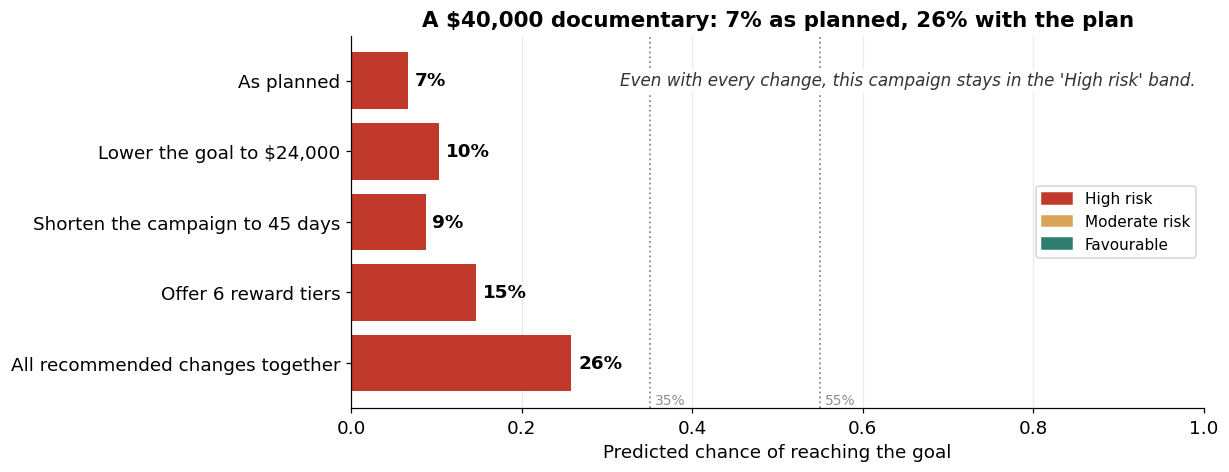

saved final_06_example_recommendation.png

The plan:
  - Lower the goal to $24,000
  - Shorten the campaign to 45 days
  - Offer 6 reward tiers ($10,$15,$20,$25,$40,$50)


In [10]:
camp = dict(goal=40000, duration=60, reward_tiers=[10, 25, 50],
            category="Film & Video", subcategory="Documentary", state="CA")
a = rec.assess(camp)
bars = [("As planned", a.probability)]
for _, r_ in a.options[a.options["recommended"]].iterrows():
    bars.append((r_["change"].split(" (")[0], r_["probability"]))
bars.append(("All recommended changes together", a.plan["probability"]))

band_color = {"High risk": CORAL, "Moderate risk": SAND, "Favourable": TEAL}
fig, ax = plt.subplots(figsize=(10, 4.4))
for i, (lab, p_) in enumerate(bars):
    ax.barh(i, p_, color=band_color[rec.band_of(p_)])
    ax.text(p_ + 0.008, i, f"{p_:.0%}", va="center", fontsize=12, fontweight="bold")
ax.set_yticks(range(len(bars))); ax.set_yticklabels([b[0] for b in bars]); ax.invert_yaxis()
for edge, name in [(BANDS[0][0], "High / Moderate"), (BANDS[1][0], "Moderate / Favourable")]:
    ax.axvline(edge, color=GREY, ls=":", lw=1.2)
ax.set_xlim(0, 1)
ax.set_xlabel("Predicted chance of reaching the goal")
ax.set_title(f"A $40,000 documentary: {a.probability:.0%} as planned, {a.plan['probability']:.0%} with the plan")
for edge in (BANDS[0][0], BANDS[1][0]):
    ax.text(edge + 0.006, len(bars) - 0.42, f"{edge:.0%}", ha="left", fontsize=9, color=GREY)
ax.text(0.99, 0.0, f"Even with every change, this campaign stays in the "
        f"'{rec.band_of(a.plan['probability'])}' band.", ha="right", va="center", fontsize=11,
        style="italic", color="#333",
        bbox=dict(facecolor="white", edgecolor="none", pad=2, alpha=0.9))
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in band_color.values()]
ax.legend(handles, band_color.keys(), loc="center right", fontsize=10)
ax.grid(axis="y", visible=False)
save(fig, "final_06_example_recommendation.png")
print("\nThe plan:")
for ch in a.plan["changes"]:
    print("  -", ch)

## 7. What the risk bands mean

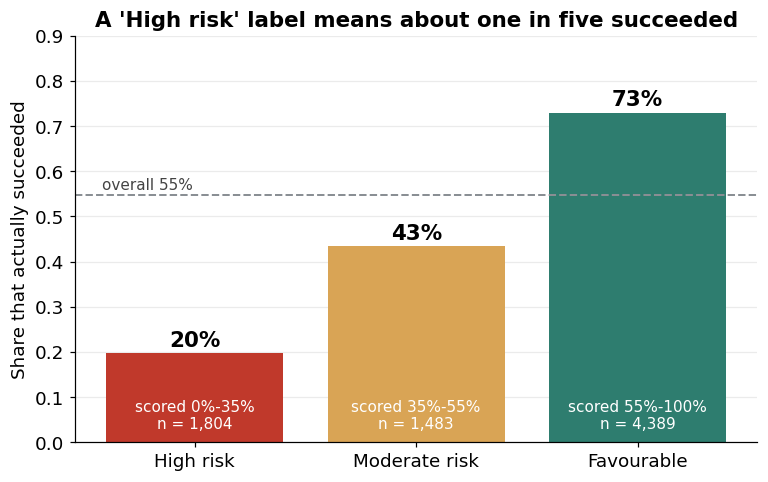

saved final_07_risk_bands.png


In [11]:
bands = pd.DataFrame([{"band": k, "rate": v["observed_rate"], "n": v["n"], "lo": v["range"][0], "hi": v["range"][1]}
                      for k, v in rec.band_rates.items()])
fig, ax = plt.subplots(figsize=(8, 4.8))
ax.bar(bands["band"], bands["rate"], color=[band_color[b] for b in bands["band"]])
for i, r_ in bands.iterrows():
    ax.text(i, r_["rate"] + 0.015, f"{r_['rate']:.0%}", ha="center", fontsize=14, fontweight="bold")
    ax.text(i, 0.03, f"scored {r_['lo']:.0%}-{r_['hi']:.0%}\nn = {r_['n']:,}", ha="center",
            color="white", fontsize=10)
ax.axhline(test["success"].mean(), color=GREY, ls="--", lw=1.3)
ax.text(-0.42, test["success"].mean() + 0.012, f"overall {test['success'].mean():.0%}", ha="left",
        fontsize=10, color="#444")
ax.set_ylim(0, 0.9); ax.set_ylabel("Share that actually succeeded")
ax.set_title("A 'High risk' label means about one in five succeeded")
ax.grid(axis="x", visible=False)
save(fig, "final_07_risk_bands.png")

## Summary

Nine figures, one per slide-sized idea: the one-slide model summary, the
data funnel, what separates winners from losers, the model comparison (with
the leakage caveat on the chart itself), calibration, lever effects, a worked
example, what the risk bands mean, and the top input features.

The model-comparison figure deliberately shows the 80% benchmark and the
variable that produces it side by side with the launch-time result, so the
gap is explained on the slide rather than left for a question.